In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("All libraries imported successfully!")

TensorFlow: 2.21.0
NumPy: 2.1.3
Pandas: 2.2.3
All libraries imported successfully!


In [3]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Tilapia_Egg_CNN")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Project folder: /content/drive/MyDrive/Tilapia_Egg_CNN


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Tilapia_Egg_CNN")
ZIP_PATH = PROJECT_DIR / "tilapia_dataset.zip"

print("ZIP file exists:", ZIP_PATH.exists())
print("ZIP path:", ZIP_PATH)


ZIP file exists: True
ZIP path: /content/drive/MyDrive/Tilapia_Egg_CNN/tilapia_dataset.zip


In [7]:
from pathlib import Path
import zipfile

PROJECT_DIR = Path("/content/drive/MyDrive/Tilapia_Egg_CNN")
ZIP_PATH = PROJECT_DIR / "tilapia_dataset.zip"
EXTRACT_PATH = Path("/content/tilapia_raw")

EXTRACT_PATH.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")
print("Location:", EXTRACT_PATH)

Dataset extracted successfully!
Location: /content/tilapia_raw


In [8]:
for path in sorted(EXTRACT_PATH.rglob("*")):
    if path.is_dir():
        print(path)

/content/tilapia_raw/dataset
/content/tilapia_raw/dataset/abnormal
/content/tilapia_raw/dataset/healthy
/content/tilapia_raw/dataset/models
/content/tilapia_raw/dataset/results
/content/tilapia_raw/dataset/train
/content/tilapia_raw/dataset/unhealthy


In [9]:
from collections import Counter

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

for folder in sorted(EXTRACT_PATH.rglob("*")):
    if folder.is_dir() and folder.name.lower() in {
        "healthy", "damaged", "infected",
        "fungal", "infected_fungal", "abnormal"
    }:
        images = [
            f for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        ]

        print(f"{folder.name}: {len(images)} images")
        print("Formats:", dict(Counter(
            f.suffix.lower() for f in images
        )))

abnormal: 0 images
Formats: {}
healthy: 40 images
Formats: {'.jpg': 40}


In [10]:
from pathlib import Path
from collections import Counter

DATASET_DIR = Path("/content/tilapia_raw/dataset")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

for folder in sorted(p for p in DATASET_DIR.rglob("*") if p.is_dir()):
    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if images:
        print(f"{folder}: {len(images)} images")
        print("  Formats:", dict(Counter(p.suffix.lower() for p in images)))

/content/tilapia_raw/dataset/healthy: 40 images
  Formats: {'.jpg': 40}
/content/tilapia_raw/dataset/unhealthy: 40 images
  Formats: {'.jpg': 40}


In [11]:
for folder_name in ["unhealthy", "train", "abnormal"]:
    folder = DATASET_DIR / folder_name

    print(f"\n--- {folder_name} ---")

    if folder.exists():
        for item in sorted(folder.iterdir()):
            if item.is_dir():
                print(f"Folder: {item.name}")
            elif item.is_file():
                print(f"File: {item.name}")
    else:
        print("Folder not found")


--- unhealthy ---
File: unhealthy_tilapia_egg_001.jpg
File: unhealthy_tilapia_egg_002.jpg
File: unhealthy_tilapia_egg_003.jpg
File: unhealthy_tilapia_egg_004.jpg
File: unhealthy_tilapia_egg_005.jpg
File: unhealthy_tilapia_egg_006.jpg
File: unhealthy_tilapia_egg_007.jpg
File: unhealthy_tilapia_egg_008.jpg
File: unhealthy_tilapia_egg_009.jpg
File: unhealthy_tilapia_egg_010.jpg
File: unhealthy_tilapia_egg_011.jpg
File: unhealthy_tilapia_egg_012.jpg
File: unhealthy_tilapia_egg_013.jpg
File: unhealthy_tilapia_egg_014.jpg
File: unhealthy_tilapia_egg_015.jpg
File: unhealthy_tilapia_egg_016.jpg
File: unhealthy_tilapia_egg_017.jpg
File: unhealthy_tilapia_egg_018.jpg
File: unhealthy_tilapia_egg_019.jpg
File: unhealthy_tilapia_egg_020.jpg
File: unhealthy_tilapia_egg_021.jpg
File: unhealthy_tilapia_egg_022.jpg
File: unhealthy_tilapia_egg_023.jpg
File: unhealthy_tilapia_egg_024.jpg
File: unhealthy_tilapia_egg_025.jpg
File: unhealthy_tilapia_egg_026.jpg
File: unhealthy_tilapia_egg_027.jpg
File: unh

In [12]:
from pathlib import Path
from collections import Counter

DATASET_DIR = Path("/content/tilapia_raw/dataset")

for class_name in ["healthy", "unhealthy"]:
    folder = DATASET_DIR / class_name

    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp",
            ".webp", ".tif", ".tiff"
        }
    ]

    print(f"\n{class_name.upper()}: {len(images)} images")
    print("Formats:", dict(Counter(p.suffix.lower() for p in images)))


HEALTHY: 40 images
Formats: {'.jpg': 40}

UNHEALTHY: 40 images
Formats: {'.jpg': 40}


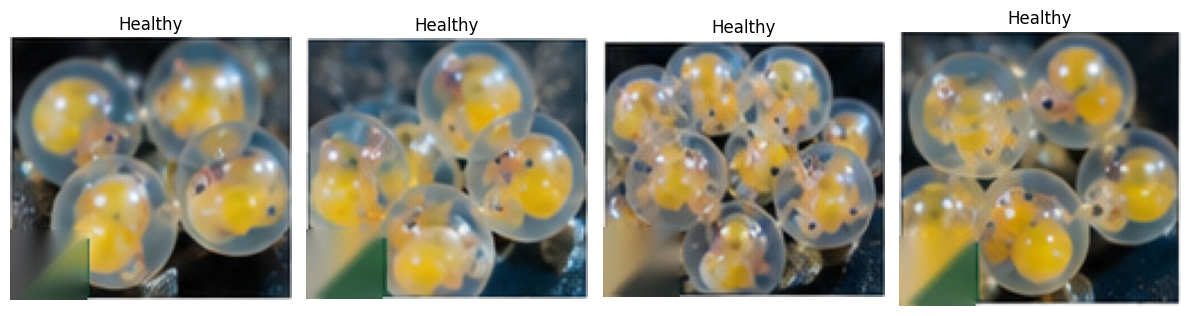

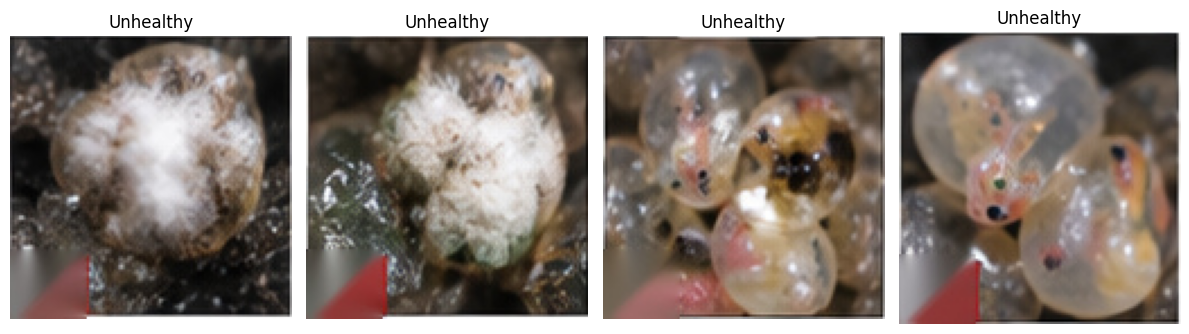

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import random

for class_name in ["healthy", "unhealthy"]:
    folder = DATASET_DIR / class_name
    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp",
            ".webp", ".tif", ".tiff"
        }
    ]

    if not images:
        print(f"No images found in {class_name}")
        continue

    sample = random.sample(images, min(4, len(images)))

    fig, axes = plt.subplots(1, len(sample), figsize=(12, 4))
    if len(sample) == 1:
        axes = [axes]

    for ax, image_path in zip(axes, sample):
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(class_name.capitalize())
        ax.axis("off")

    plt.tight_layout()
    plt.show()

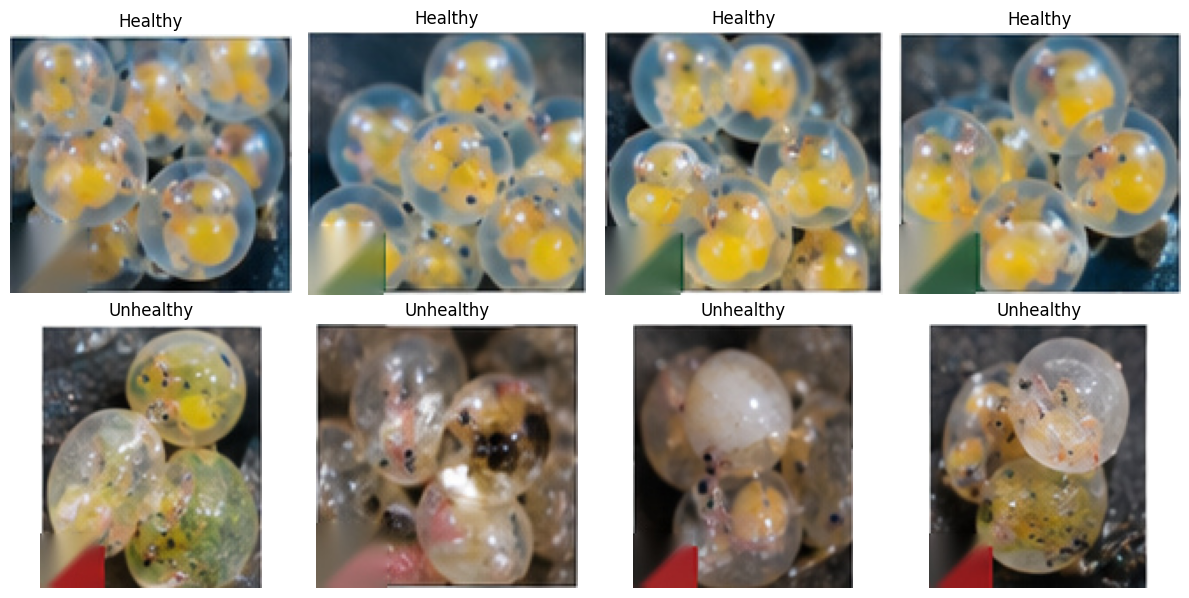

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

DATASET_DIR = Path("/content/tilapia_raw/dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, class_name in enumerate(["healthy", "unhealthy"]):
    folder = DATASET_DIR / class_name
    image_paths = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    samples = random.sample(image_paths, min(4, len(image_paths)))

    for col, image_path in enumerate(samples):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name.capitalize())
        axes[row, col].axis("off")

    for col in range(len(samples), 4):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [15]:
from collections import Counter
from PIL import Image

dimensions = Counter()
colour_modes = Counter()
unreadable_files = []

for class_name in ["healthy", "unhealthy"]:
    folder = DATASET_DIR / class_name

    for image_path in folder.rglob("*"):
        if not image_path.is_file():
            continue
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(image_path) as img:
                dimensions[img.size] += 1
                colour_modes[img.mode] += 1
        except Exception as e:
            unreadable_files.append((str(image_path), str(e)))

print("Original image dimensions:")
for size, count in dimensions.most_common():
    print(f"{size}: {count} images")

print("\nColour modes:", dict(colour_modes))
print("Unreadable files:", len(unreadable_files))

Original image dimensions:
(125, 126): 12 images
(125, 122): 6 images
(125, 119): 6 images
(125, 116): 6 images
(125, 114): 6 images
(125, 130): 6 images
(125, 150): 6 images
(126, 126): 4 images
(126, 122): 2 images
(126, 116): 2 images
(126, 119): 2 images
(126, 114): 2 images
(124, 126): 2 images
(126, 150): 2 images
(123, 126): 2 images
(126, 130): 2 images
(124, 114): 1 images
(123, 122): 1 images
(124, 119): 1 images
(124, 116): 1 images
(123, 114): 1 images
(124, 122): 1 images
(123, 116): 1 images
(123, 119): 1 images
(123, 150): 1 images
(124, 130): 1 images
(123, 130): 1 images
(124, 150): 1 images

Colour modes: {'RGB': 80}
Unreadable files: 0


In [16]:
from pathlib import Path
from PIL import Image, ImageOps, UnidentifiedImageError
from collections import Counter

# Original dataset
DATASET_DIR = Path("/content/tilapia_raw/dataset")

# Destination for processed images
PROCESSED_DIR = Path("/content/tilapia_processed")

# Standard image size for our CNN
IMAGE_SIZE = (224, 224)

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# Create destination folders
for class_name in ["healthy", "unhealthy"]:
    (PROCESSED_DIR / class_name).mkdir(
        parents=True,
        exist_ok=True
    )

processed_counts = Counter()
failed_images = []

# Process each class
for class_name in ["healthy", "unhealthy"]:

    source_folder = DATASET_DIR / class_name
    destination_folder = PROCESSED_DIR / class_name

    image_paths = sorted(
        p for p in source_folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    for index, image_path in enumerate(image_paths, start=1):
        try:
            with Image.open(image_path) as img:
                # Correct orientation using image metadata
                img = ImageOps.exif_transpose(img)

                # Convert to RGB and resize
                img = img.convert("RGB")
                img = img.resize(
                    IMAGE_SIZE,
                    Image.Resampling.LANCZOS
                )

                # Save a standardised JPEG copy
                output_path = (
                    destination_folder
                    / f"{class_name}_{index:03d}.jpg"
                )
                img.save(output_path, "JPEG", quality=95)

                processed_counts[class_name] += 1

        except (OSError, ValueError, UnidentifiedImageError) as error:
            failed_images.append((str(image_path), str(error)))

print("PREPROCESSING COMPLETE")
print("-" * 35)

for class_name in ["healthy", "unhealthy"]:
    print(f"{class_name.capitalize()}: "
          f"{processed_counts[class_name]} images")

print("Total processed:", sum(processed_counts.values()))
print("Failed images:", len(failed_images))
print("Output folder:", PROCESSED_DIR)

PREPROCESSING COMPLETE
-----------------------------------
Healthy: 40 images
Unhealthy: 40 images
Total processed: 80
Failed images: 0
Output folder: /content/tilapia_processed


In [17]:
from PIL import Image

for class_name in ["healthy", "unhealthy"]:
    folder = PROCESSED_DIR / class_name
    images = sorted(folder.glob("*.jpg"))

    print(f"\n{class_name.capitalize()}: {len(images)} images")

    if images:
        with Image.open(images[0]) as img:
            print("Sample filename:", images[0].name)
            print("Image dimensions:", img.size)
            print("Colour mode:", img.mode)


Healthy: 40 images
Sample filename: healthy_001.jpg
Image dimensions: (224, 224)
Colour mode: RGB

Unhealthy: 40 images
Sample filename: unhealthy_001.jpg
Image dimensions: (224, 224)
Colour mode: RGB


In [18]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter
import shutil

# Input and output folders
PROCESSED_DIR = Path("/content/tilapia_processed")
SPLIT_DIR = Path("/content/tilapia_split")

CLASSES = ["healthy", "unhealthy"]
SEED = 42

# Create a fresh output folder for this split
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

for split in ["train", "validation", "test"]:
    for class_name in CLASSES:
        (SPLIT_DIR / split / class_name).mkdir(
            parents=True, exist_ok=True
        )

# Split each class separately to preserve class balance
for class_name in CLASSES:
    image_paths = sorted(
        (PROCESSED_DIR / class_name).glob("*.jpg")
    )

    if len(image_paths) < 3:
        raise ValueError(
            f"Not enough images in class: {class_name}"
        )

    # 70% training, 30% temporary holdout
    train_images, remaining_images = train_test_split(
        image_paths,
        test_size=0.30,
        random_state=SEED
    )

    # Divide the remaining images equally into validation and test
    val_images, test_images = train_test_split(
        remaining_images,
        test_size=0.50,
        random_state=SEED
    )

    splits = {
        "train": train_images,
        "validation": val_images,
        "test": test_images
    }

    for split_name, paths in splits.items():
        for image_path in paths:
            destination = SPLIT_DIR / split_name / class_name / image_path.name
            shutil.copy2(image_path, destination)

print("DATASET SPLIT COMPLETE\n")

for split_name in ["train", "validation", "test"]:
    print(f"{split_name.upper()}")

    total = 0
    for class_name in CLASSES:
        count = len(
            list((SPLIT_DIR / split_name / class_name).glob("*.jpg"))
        )
        print(f"  {class_name}: {count}")
        total += count

    print(f"  Total: {total}\n")

DATASET SPLIT COMPLETE

TRAIN
  healthy: 28
  unhealthy: 28
  Total: 56

VALIDATION
  healthy: 6
  unhealthy: 6
  Total: 12

TEST
  healthy: 6
  unhealthy: 6
  Total: 12



In [19]:
import tensorflow as tf
import numpy as np

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8

SPLIT_DIR = "/content/tilapia_split"

# Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{SPLIT_DIR}/train",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

# Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{SPLIT_DIR}/validation",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Load test images
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{SPLIT_DIR}/test",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Confirm class order
print("Class names:", train_ds.class_names)

Found 56 files belonging to 2 classes.
Found 12 files belonging to 2 classes.
Found 12 files belonging to 2 classes.
Class names: ['healthy', 'unhealthy']


In [20]:
# Scale pixel values from 0–255 to 0–1
normalisation_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (
        normalisation_layer(images), labels
    )
)

val_ds = val_ds.map(
    lambda images, labels: (
        normalisation_layer(images), labels
    )
)

test_ds = test_ds.map(
    lambda images, labels: (
        normalisation_layer(images), labels
    )
)

print("Normalisation applied to all three datasets.")

Normalisation applied to all three datasets.


In [21]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

Image batch shape: (8, 224, 224, 3)
Label batch shape: (8, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [22]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 1)
    )
], name="tilapia_image_augmentation")

print("Image augmentation pipeline created.")

Image augmentation pipeline created.


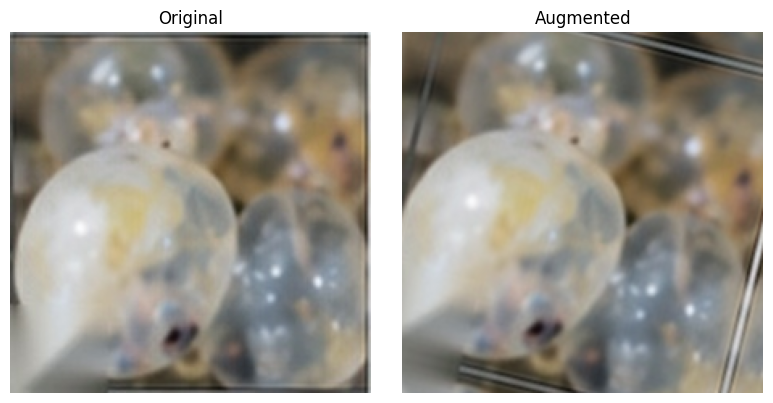

In [23]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):
    original = images[0:1]
    augmented = data_augmentation(original, training=True)

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(original[0].numpy())
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(tf.clip_by_value(
        augmented[0], 0, 1
    ).numpy())
    plt.title("Augmented")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
from pathlib import Path
import shutil

# Destination folder in Google Drive
DRIVE_DIR = Path("/content/drive/MyDrive/Tilapia_Egg_CNN")

# Save the resized and standardised images
processed_destination = DRIVE_DIR / "tilapia_processed"
shutil.copytree(
    "/content/tilapia_processed",
    processed_destination,
    dirs_exist_ok=True
)

# Save the training, validation and testing datasets
split_destination = DRIVE_DIR / "tilapia_split"
shutil.copytree(
    "/content/tilapia_split",
    split_destination,
    dirs_exist_ok=True
)

print("DATASET SAVED SUCCESSFULLY")
print("Processed images:", processed_destination)
print("Training, validation and test sets:", split_destination)

In [24]:
from pathlib import Path

DRIVE_SPLIT_DIR = Path(
    "/content/drive/MyDrive/Tilapia_Egg_CNN/tilapia_split"
)

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_name in ["healthy", "unhealthy"]:
        folder = DRIVE_SPLIT_DIR / split / class_name
        count = len(list(folder.glob("*")))
        print(f"{class_name}: {count} images")


TRAIN
healthy: 0 images
unhealthy: 0 images

VALIDATION
healthy: 0 images
unhealthy: 0 images

TEST
healthy: 0 images
unhealthy: 0 images


In [25]:
from pathlib import Path

folders_to_check = [
    Path("/content/tilapia_split"),
    Path("/content/drive/MyDrive/Tilapia_Egg_CNN/tilapia_split"),
    Path("/content/tilapia_processed"),
]

for folder in folders_to_check:
    print(f"\nChecking: {folder}")
    print("Folder exists:", folder.exists())

    if folder.exists():
        files = [p for p in folder.rglob("*") if p.is_file()]
        print("Total files:", len(files))
        print("Sample paths:")
        for path in files[:5]:
            print(" ", path)


Checking: /content/tilapia_split
Folder exists: True
Total files: 80
Sample paths:
  /content/tilapia_split/test/healthy/healthy_016.jpg
  /content/tilapia_split/test/healthy/healthy_007.jpg
  /content/tilapia_split/test/healthy/healthy_020.jpg
  /content/tilapia_split/test/healthy/healthy_026.jpg
  /content/tilapia_split/test/healthy/healthy_013.jpg

Checking: /content/drive/MyDrive/Tilapia_Egg_CNN/tilapia_split
Folder exists: False

Checking: /content/tilapia_processed
Folder exists: True
Total files: 80
Sample paths:
  /content/tilapia_processed/healthy/healthy_029.jpg
  /content/tilapia_processed/healthy/healthy_002.jpg
  /content/tilapia_processed/healthy/healthy_001.jpg
  /content/tilapia_processed/healthy/healthy_015.jpg
  /content/tilapia_processed/healthy/healthy_016.jpg


In [26]:
from pathlib import Path
import shutil

DRIVE_DIR = Path("/content/drive/MyDrive/Tilapia_Egg_CNN")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# Copy processed images
shutil.copytree(
    "/content/tilapia_processed",
    DRIVE_DIR / "tilapia_processed",
    dirs_exist_ok=True
)

# Copy training, validation and testing images
shutil.copytree(
    "/content/tilapia_split",
    DRIVE_DIR / "tilapia_split",
    dirs_exist_ok=True
)

print("Both datasets copied to Google Drive successfully.")

Both datasets copied to Google Drive successfully.


In [27]:
from pathlib import Path

DRIVE_SPLIT_DIR = Path(
    "/content/drive/MyDrive/Tilapia_Egg_CNN/tilapia_split"
)

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_name in ["healthy", "unhealthy"]:
        folder = DRIVE_SPLIT_DIR / split / class_name

        image_count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in
            {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        ) if folder.exists() else 0

        print(f"{class_name}: {image_count} images")


TRAIN
healthy: 28 images
unhealthy: 28 images

VALIDATION
healthy: 6 images
unhealthy: 6 images

TEST
healthy: 6 images
unhealthy: 6 images


BUILDING THE CNN MODEL


In [31]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.13.2


In [33]:
PROJECT_DIR = "/content/drive/MyDrive/Tilapia_Egg_CNN"

TRAIN_DIR = os.path.join(
    PROJECT_DIR, "tilapia_split", "train"
)

VAL_DIR = os.path.join(
    PROJECT_DIR, "tilapia_split", "validation"
)

TEST_DIR = os.path.join(
    PROJECT_DIR, "tilapia_split", "test"
)

print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Validation folder exists:", os.path.exists(VAL_DIR))
print("Testing folder exists:", os.path.exists(TEST_DIR))

Training folder exists: True
Validation folder exists: True
Testing folder exists: True


In [34]:
from pathlib import Path

for name, folder in [
    ("Training", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Testing", TEST_DIR)
]:
    print(f"\n{name}")

    for class_name in sorted(os.listdir(folder)):
        class_path = Path(folder) / class_name

        if class_path.is_dir():
            image_count = sum(
                1 for file in class_path.iterdir()
                if file.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".bmp"
                }
            )

            print(f"{class_name}: {image_count} images")


Training
healthy: 28 images
unhealthy: 28 images

Validation
healthy: 6 images
unhealthy: 6 images

Testing
healthy: 6 images
unhealthy: 6 images


In [35]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42

CLASS_NAMES = ["healthy", "unhealthy"]

train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

val_ds = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("\nDatasets loaded successfully.")
print("Class order:", CLASS_NAMES)

Found 56 files belonging to 2 classes.
Found 12 files belonging to 2 classes.
Found 12 files belonging to 2 classes.

Datasets loaded successfully.
Class order: ['healthy', 'unhealthy']


In [36]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())
print("First 8 labels:", labels.numpy().flatten())

Image batch shape: (8, 224, 224, 3)
Label batch shape: (8, 1)
Minimum pixel value: 0.0
Maximum pixel value: 255.0
First 8 labels: [1. 1. 1. 0. 1. 0. 0. 1.]


In [37]:
data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(0.05),
        layers.RandomFlip("horizontal"),
        layers.RandomBrightness(0.10, value_range=(0, 1)),
    ],
    name="data_augmentation"
)

print("Data augmentation configured.")

Data augmentation configured.


In [38]:
model = keras.Sequential(
    [
        keras.Input(shape=(224, 224, 3)),

        # Convert pixel values from 0–255 to 0–1
        layers.Rescaling(1.0 / 255),

        # Apply augmentation during training
        data_augmentation,

        # First convolution block
        layers.Conv2D(
            16, (3, 3), activation="relu", padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        # Second convolution block
        layers.Conv2D(
            32, (3, 3), activation="relu", padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        # Third convolution block
        layers.Conv2D(
            64, (3, 3), activation="relu", padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        # Convert feature maps into a vector
        layers.Flatten(),

        # Learn combinations of visual features
        layers.Dense(64, activation="relu"),

        # Reduce overfitting
        layers.Dropout(0.4),

        # Binary classification output
        layers.Dense(1, activation="sigmoid"),
    ],
    name="tilapia_egg_cnn"
)

model.summary()

Model: "tilapia_egg_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,234,977 (12.34 MB)

 Trainable params: 3,234,977 (12.34 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


In [40]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 314ms/step - accuracy: 0.4286 - loss: 0.7782 - val_accuracy: 0.5000 - val_loss: 0.6639
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 289ms/step - accuracy: 0.5714 - loss: 0.6645 - val_accuracy: 0.5000 - val_loss: 0.5980
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 457ms/step - accuracy: 0.5893 - loss: 0.5695 - val_accuracy: 1.0000 - val_loss: 0.4476
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 317ms/step - accuracy: 0.9107 - loss: 0.4486 - val_accuracy: 0.9167 - val_loss: 0.2891
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 315ms/step - accuracy: 0.8393 - loss: 0.3770 - val_accuracy: 1.0000 - val_loss: 0.1888
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 312ms/step - accuracy: 0.9464 - loss: 0.3078 - val_accuracy: 1.0000 - val_loss: 0.1768
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 306ms/step - accuracy: 0.9643 - loss: 0.1306 - val_accuracy: 1.0000 - val_loss: 0.0971
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 464ms/step - accuracy: 0.9643 - loss: 0.1119 - val_accuracy: 1.0000 - val_loss:

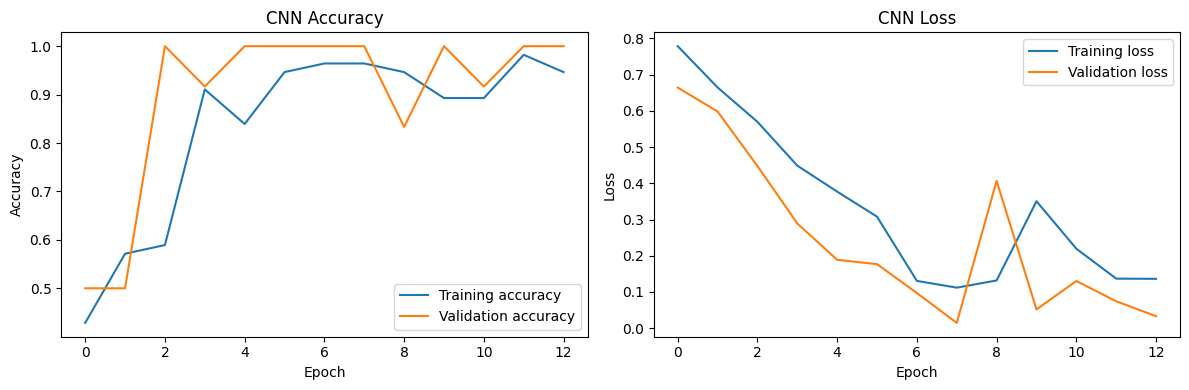

In [41]:
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [42]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 1.0000 - loss: 0.0209
Test Loss: 0.0209
Test Accuracy: 100.00%


In [43]:
import numpy as np

y_true = np.concatenate([
    labels.numpy().flatten()
    for images, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds).flatten()

y_pred = (y_prob >= 0.5).astype(int)

print("Actual labels:     ", y_true)
print("Predicted labels:  ", y_pred)
print("Unhealthy probability:", np.round(y_prob, 3))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
Actual labels:      [0 0 0 0 0 0 1 1 1 1 1 1]
Predicted labels:   [0 0 0 0 0 0 1 1 1 1 1 1]
Unhealthy probability: [0.    0.    0.    0.002 0.    0.002 0.977 0.982 0.964 0.984 0.926 0.928]


              precision    recall  f1-score   support

     Healthy       1.00      1.00      1.00         6
   Unhealthy       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



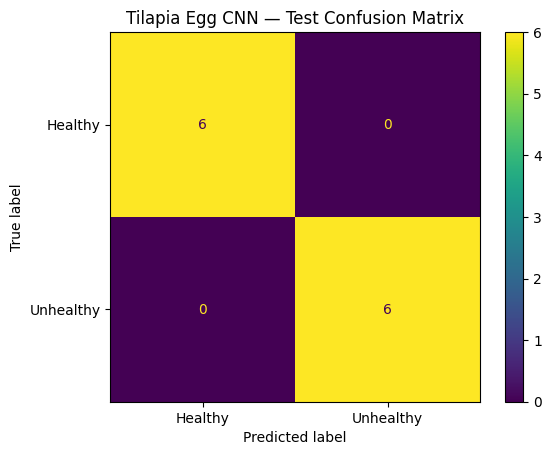

In [45]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Healthy", "Unhealthy"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Unhealthy"]
)

display.plot()
plt.title("Tilapia Egg CNN — Test Confusion Matrix")
plt.show()

In [46]:

import os

MODEL_PATH = "/content/drive/MyDrive/Tilapia_Egg_CNN/models/tilapia_egg_cnn_week4.keras"

if os.path.exists(MODEL_PATH):
    print("SUCCESS: CNN model exists!")
    print("File size:", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2), "MB")
    print("Saved at:", MODEL_PATH)
else:
    print("Model file not found. Check the save step and Google Drive connection.")


Model file not found. Check the save step and Google Drive connection.


In [47]:
import os

print("Drive mounted:", os.path.isdir("/content/drive/MyDrive"))
print("Project folder exists:",
      os.path.exists("/content/drive/MyDrive/Tilapia_Egg_CNN"))

print("Model variable available:", "model" in globals())

Drive mounted: True
Project folder exists: True
Model variable available: True


In [48]:
import os

# Define the model folder in Google Drive
MODEL_DIR = "/content/drive/MyDrive/Tilapia_Egg_CNN/models"

# Create the folder if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)

# Define the model file path
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "tilapia_egg_cnn_week4.keras"
)

# Save the trained CNN
model.save(MODEL_PATH)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: /content/drive/MyDrive/Tilapia_Egg_CNN/models/tilapia_egg_cnn_week4.keras


In [49]:
import os

if os.path.isfile(MODEL_PATH):
    print("SUCCESS: Model file exists.")
    print(f"File size: {os.path.getsize(MODEL_PATH):,} bytes")
    print("Full path:", MODEL_PATH)
else:
    print("ERROR: Model file was not created.")

SUCCESS: Model file exists.
File size: 38,879,816 bytes
Full path: /content/drive/MyDrive/Tilapia_Egg_CNN/models/tilapia_egg_cnn_week4.keras


In [50]:
import os

MODEL_DIR = "/content/drive/MyDrive/Tilapia_Egg_CNN/models"

print("Model folder exists:", os.path.isdir(MODEL_DIR))

if os.path.isdir(MODEL_DIR):
    print("\nContents of models folder:")

    for file in os.listdir(MODEL_DIR):
        file_path = os.path.join(MODEL_DIR, file)
        print(f"{file} — {os.path.getsize(file_path):,} bytes")

Model folder exists: True

Contents of models folder:
tilapia_egg_cnn_week4.keras — 38,879,816 bytes


In [51]:
import tensorflow as tf
from tensorflow import keras

MODEL_PATH = (
    "/content/drive/MyDrive/Tilapia_Egg_CNN/"
    "models/tilapia_egg_cnn_week4.keras"
)

loaded_model = keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Input shape:", loaded_model.input_shape)
print("Output shape:", loaded_model.output_shape)

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [52]:
import hashlib
import os

DATASET_DIR = (
    "/content/drive/MyDrive/Tilapia_Egg_CNN/tilapia_split"
)

splits = ["train", "validation", "test"]
hashes_by_split = {}

for split in splits:
    hashes = {}

    split_dir = os.path.join(DATASET_DIR, split)

    for root, dirs, files in os.walk(split_dir):
        for filename in files:
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                path = os.path.join(root, filename)

                with open(path, "rb") as f:
                    digest = hashlib.sha256(f.read()).hexdigest()

                hashes.setdefault(digest, []).append(path)

    hashes_by_split[split] = hashes
    print(f"{split}: {sum(map(len, hashes.values()))} images")

print("\nChecking for identical files across splits...")

found_duplicates = False

for i, split_a in enumerate(splits):
    for split_b in splits[i + 1:]:
        common = (
            set(hashes_by_split[split_a])
            & set(hashes_by_split[split_b])
        )

        if common:
            found_duplicates = True
            print(f"\nDuplicates between {split_a} and {split_b}:")
            for digest in common:
                print("A:", hashes_by_split[split_a][digest])
                print("B:", hashes_by_split[split_b][digest])

if not found_duplicates:
    print("No byte-identical images found across splits.")

train: 56 images
validation: 12 images
test: 12 images

Checking for identical files across splits...
No byte-identical images found across splits.


In [53]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from PIL import Image

MODEL_PATH = (
    "/content/drive/MyDrive/Tilapia_Egg_CNN/"
    "models/tilapia_egg_cnn_week4.keras"
)

model = keras.models.load_model(MODEL_PATH)

print("Saved CNN model loaded successfully.")

Saved CNN model loaded successfully.


In [55]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

image_filename = next(iter(uploaded.keys()))

print("Selected image:", image_filename)

Saving unhealthy_02.jpg to unhealthy_02.jpg
Selected image: unhealthy_02.jpg


Image batch shape: (1, 224, 224, 3)
Pixel range: 0.0 to 255.0


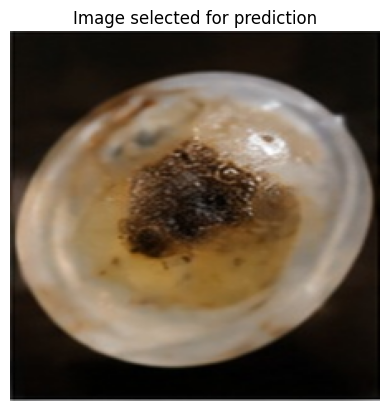

In [56]:
image = Image.open(image_filename).convert("RGB")
image = image.resize((224, 224))

image_array = np.array(image, dtype=np.float32)
image_batch = np.expand_dims(image_array, axis=0)

print("Image batch shape:", image_batch.shape)
print("Pixel range:", image_batch.min(), "to", image_batch.max())

plt.imshow(image)
plt.title("Image selected for prediction")
plt.axis("off")
plt.show()

In [57]:
prediction = model.predict(image_batch, verbose=0)

unhealthy_probability = float(prediction[0][0])

if unhealthy_probability >= 0.5:
    predicted_class = "Unhealthy"
else:
    predicted_class = "Healthy"

print("Predicted class:", predicted_class)
print(f"Unhealthy probability: {unhealthy_probability:.2%}")
print(f"Healthy probability: {(1 - unhealthy_probability):.2%}")

Predicted class: Unhealthy
Unhealthy probability: 94.08%
Healthy probability: 5.92%


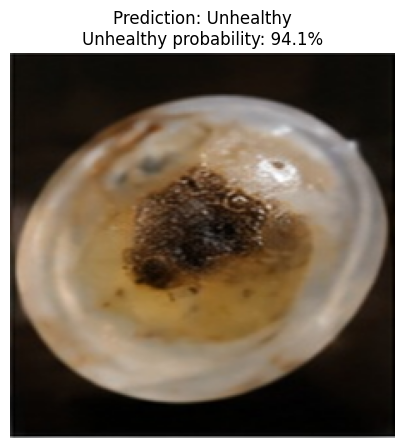

In [58]:
plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Unhealthy probability: {unhealthy_probability:.1%}"
)
plt.axis("off")
plt.show()